# Actividad Práctica: Árbol de Decisión y Random Forest para Prevenir Riesgos
**Curso:** Agentes Inteligentes - Practica 10  
**Caso:** Predicción de Deserción Universitaria (`deserta`)  
**Fuente:** Datos sintéticos con fines didácticos inspirados en indicadores educativos de retención (Minedu-SIRIES).

## Parte 1: El árbol a mano (14 correos de Phishing)

### 1. Cálculo de impureza de Gini ($Gini = 1 - \sum p_i^2$)

- **Gini total del nodo raíz (14 correos: 7 Sí, 7 No):**
  $$Gini(D) = 1 - \left((7/14)^2 + (7/14)^2\right) = 1 - (0.25 + 0.25) = 0.500$$

- **Variable Urgencia:**
  - *Alta (4 correos: 4 Sí, 0 No):* $Gini = 1 - (1^2 + 0^2) = 0.0$
  - *Media (5 correos: 3 Sí, 2 No):* $Gini = 1 - ((3/5)^2 + (2/5)^2) = 1 - (0.36 + 0.16) = 0.480$
  - *Baja (5 correos: 0 Sí, 5 No):* $Gini = 1 - (0^2 + 1^2) = 0.0$
  - **Gini ponderado Urgencia:** $(4/14)(0.0) + (5/14)(0.480) + (5/14)(0.0) = \mathbf{0.171}$

- **Variable Remitente:**
  - *Desconocido (8 correos: 5 Sí, 3 No):* $Gini = 1 - ((5/8)^2 + (3/8)^2) = 0.4688$
  - *Conocido (6 correos: 2 Sí, 4 No):* $Gini = 1 - ((2/6)^2 + (4/6)^2) = 0.4444$
  - **Gini ponderado Remitente:** $(8/14)(0.4688) + (6/14)(0.4444) = \mathbf{0.458}$

- **Variable Adjunto:**
  - *Sí (7 correos: 4 Sí, 3 No):* $Gini = 1 - ((4/7)^2 + (3/7)^2) = 0.4898$
  - *No (7 correos: 3 Sí, 4 No):* $Gini = 1 - ((3/7)^2 + (4/7)^2) = 0.4898$
  - **Gini ponderado Adjunto:** $(7/14)(0.4898) + (7/14)(0.4898) = \mathbf{0.490}$

- **Variable Enlace corto:**
  - *Sí (7 correos: 4 Sí, 3 No):* $Gini = 0.4898$
  - *No (7 correos: 3 Sí, 4 No):* $Gini = 0.4898$
  - **Gini ponderado Enlace corto:** $\mathbf{0.490}$

**Decisión del nodo raíz:** Se selecciona **Urgencia** por tener el menor Gini ponderado ($0.171$), siendo la variable que más reduce la impureza.

---

### 2. Reglas del árbol manual:
1. **SI** Urgencia = "Alta" **ENTONCES** Phishing = Sí
2. **SI** Urgencia = "Baja" **ENTONCES** Phishing = No
3. **SI** Urgencia = "Media" **Y** Remitente = "Desconocido" **ENTONCES** Phishing = Sí
4. **SI** Urgencia = "Media" **Y** Remitente = "Conocido" **ENTONCES** Phishing = No
5. **EN OTRO CASO** Phishing = No

*(Adjunta la foto de tu desarrollo en papel en esta misma carpeta y asegúrate de nombrarla `arbol_mano.png`)*  
![Árbol a mano](arbol_mano.png)

In [7]:
# Parte 0: Generación de datos sintéticos (Caso Deserción) e importaciones
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report

np.random.seed(42)
n_filas = 200

# 5 variables numéricas predictoras
promedio_ponderado = np.random.normal(12.8, 2.8, n_filas).clip(5, 20)
porcentaje_asistencia = np.random.normal(78, 14, n_filas).clip(30, 100)
cursos_desaprobados = np.random.poisson(1.4, n_filas).clip(0, 6)
dias_retraso_pension = np.random.exponential(12, n_filas).clip(0, 90)
horas_trabajo_semana = np.random.choice([0, 10, 20, 30, 40], n_filas, p=[0.4, 0.2, 0.2, 0.1, 0.1])

# Lógica estocástica de deserción
riesgo = (
    (promedio_ponderado < 11.5) * 0.45 +
    (porcentaje_asistencia < 70) * 0.30 +
    (cursos_desaprobados >= 2) * 0.25 +
    (dias_retraso_pension > 30) * 0.20
)
deserta = np.where(np.random.rand(n_filas) < riesgo, 1, 0)

CASO, OBJETIVO = "Desercion", "deserta"
df = pd.DataFrame({
    'promedio_ponderado': promedio_ponderado.round(1),
    'porcentaje_asistencia': porcentaje_asistencia.round(0),
    'cursos_desaprobados': cursos_desaprobados,
    'dias_retraso_pension': dias_retraso_pension.round(0),
    'horas_trabajo_semana': horas_trabajo_semana,
    OBJETIVO: deserta
})

print(f"Dimensiones del dataset: {df.shape}")
df.head()

Dimensiones del dataset: (200, 6)


,promedio_ponderado,porcentaje_asistencia,cursos_desaprobados,dias_retraso_pension,horas_trabajo_semana,deserta
0,14.2,83.0,1,33.0,40,1
1,12.4,86.0,0,16.0,20,0
2,14.6,93.0,6,3.0,0,0
3,17.1,93.0,1,0.0,20,0
4,12.1,59.0,0,4.0,10,0


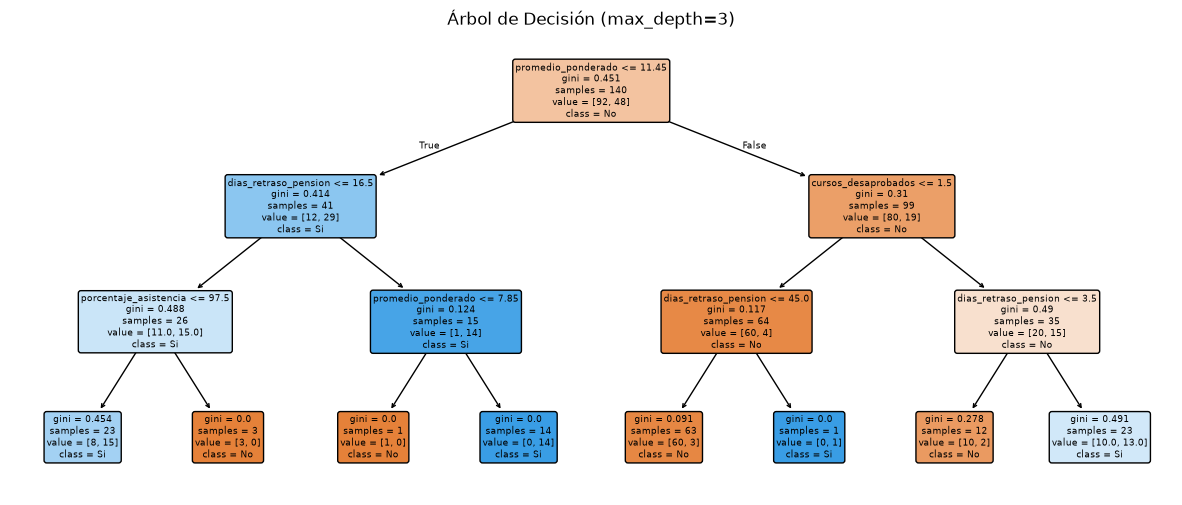

--- Reglas del árbol ---
|--- promedio_ponderado <= 11.45
|   |--- dias_retraso_pension <= 16.50
|   |   |--- porcentaje_asistencia <= 97.50
|   |   |   |--- class: 1
|   |   |--- porcentaje_asistencia >  97.50
|   |   |   |--- class: 0
|   |--- dias_retraso_pension >  16.50
|   |   |--- promedio_ponderado <= 7.85
|   |   |   |--- class: 0
|   |   |--- promedio_ponderado >  7.85
|   |   |   |--- class: 1
|--- promedio_ponderado >  11.45
|   |--- cursos_desaprobados <= 1.50
|   |   |--- dias_retraso_pension <= 45.00
|   |   |   |--- class: 0
|   |   |--- dias_retraso_pension >  45.00
|   |   |   |--- class: 1
|   |--- cursos_desaprobados >  1.50
|   |   |--- dias_retraso_pension <= 3.50
|   |   |   |--- class: 0
|   |   |--- dias_retraso_pension >  3.50
|   |   |   |--- class: 1

Entrenamiento: 1.0
Prueba:        0.717


In [8]:
# Parte 2: Tu árbol en Python
X = df.drop(columns=OBJETIVO)
y = df[OBJETIVO]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

arbol = DecisionTreeClassifier(max_depth=3, random_state=42)
arbol.fit(X_tr, y_tr)

plt.figure(figsize=(15, 6))
plot_tree(arbol, feature_names=list(X.columns), class_names=["No", "Si"], filled=True, rounded=True)
plt.title("Árbol de Decisión (max_depth=3)")
plt.show()

print("--- Reglas del árbol ---")
print(export_text(arbol, feature_names=list(X.columns)))

# Comprobación de sobreajuste con árbol sin límite
libre = DecisionTreeClassifier(random_state=42).fit(X_tr, y_tr)
print("Entrenamiento:", round(libre.score(X_tr, y_tr), 3))
print("Prueba:       ", round(libre.score(X_te, y_te), 3))

### Respuestas Parte 2:
1. **¿Qué variable eligió el árbol como raíz? ¿Tiene sentido para tu caso?**
   - El árbol eligió `promedio_ponderado` (umbral $\le 11.45$). Tiene total sentido académico y práctico, pues un rendimiento reprobatorio o al límite de la nota mínima aprobatoria es el detonante principal de riesgo y desmotivación en la carrera.

2. **Escribe dos reglas del árbol en palabras simples:**
   - *Regla 1 (Riesgo Crítico / Deserta = Sí):* SI el promedio ponderado es menor o igual a 11.45 Y los días de retraso en la pensión superan los 16.5 días Y el promedio ponderado supera los 7.85 ENTONCES el modelo predice que el estudiante desertará (Deserta = Sí con 14 de 14 casos exactos).
   - *Regla 2 (Permanencia / Deserta = No):* SI el promedio ponderado es mayor a 11.45 Y los cursos desaprobados son menores o iguales a 1.5 (es decir, máximo 1 curso jalado) Y el retraso de pensión es menor o igual a 45 días ENTONCES el modelo predice que el estudiante continuará sus estudios (Deserta = No con 60 de 63 casos).

3. **¿Por qué el árbol sin límite acierta casi el 100% en entrenamiento pero menos en prueba?**
   - Se debe al **sobreajuste (overfitting)**. Al no restringir la profundidad, el árbol genera ramas hiperespecíficas hasta memorizar casos particulares y ruido estadístico del conjunto de entrenamiento. Al enfrentarse a registros nuevos del conjunto de prueba (`X_te`), pierde capacidad de generalización y su exactitud decae notablemente.

ÁRBOL
Matriz de confusión [[VN, FP], [FN, VP]]:
[[24 15]
 [ 2 19]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.92      0.62      0.74        39
           1       0.56      0.90      0.69        21

    accuracy                           0.72        60
   macro avg       0.74      0.76      0.71        60
weighted avg       0.80      0.72      0.72        60

RANDOM FOREST
Matriz de confusión [[VN, FP], [FN, VP]]:
[[32  7]
 [ 6 15]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.84      0.82      0.83        39
           1       0.68      0.71      0.70        21

    accuracy                           0.78        60
   macro avg       0.76      0.77      0.76        60
weighted avg       0.79      0.78      0.78        60



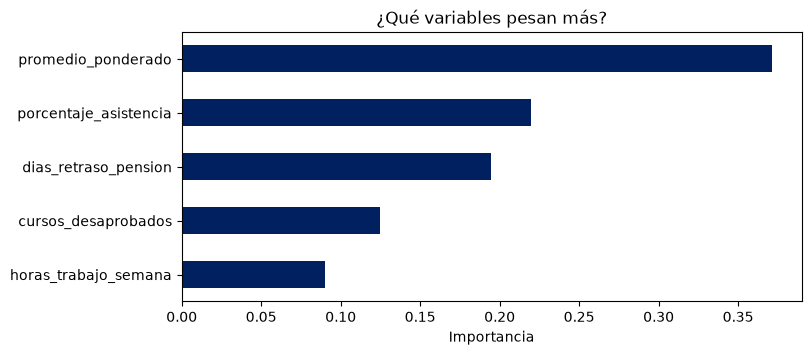

In [9]:
# Parte 3: Random Forest y comparación
bosque = RandomForestClassifier(n_estimators=100, random_state=42)
bosque.fit(X_tr, y_tr)

for nombre, modelo in [("ÁRBOL", arbol), ("RANDOM FOREST", bosque)]:
    pred = modelo.predict(X_te)
    print("=" * 35)
    print(nombre)
    print("=" * 35)
    print("Matriz de confusión [[VN, FP], [FN, VP]]:")
    print(confusion_matrix(y_te, pred))
    print("\nReporte de clasificación:")
    print(classification_report(y_te, pred))

plt.figure(figsize=(8, 3.5))
pd.Series(bosque.feature_importances_, index=X.columns).sort_values().plot.barh(color="#002060")
plt.title("¿Qué variables pesan más?")
plt.xlabel("Importancia")
plt.show()

### Tabla comparativa (Clase 1 = Deserta)

| Modelo | Accuracy | Recall clase 1 | F1 clase 1 | VP | FN |
| :--- | :---: | :---: | :---: | :---: | :---: |
| Árbol (profundidad 3) | 0.72 | 0.90 | 0.69 | 19 | 2 |
| Random Forest (100 árboles) | 0.78 | 0.71 | 0.70 | 15 | 6 |

#### Respuestas Parte 3:
1. **¿Qué modelo tiene mejor F1? ¿Por cuánto?**
   - El **Random Forest** obtiene un F1-score ligeramente superior (0.70 frente a 0.69 del árbol, superándolo por 0.01 o 1%)[cite: 4]. Aunque el árbol tuvo un recall mayor al ser más agresivo clasificando positivos, el Random Forest logra una precisión mucho más alta reduciendo los falsos positivos (de 15 a 7) y alcanzando una mejor exactitud global (78% frente a 72%)[cite: 4].
2. **¿Qué significa un FN en tu caso? ¿Es peor que un FP? Explica en dos líneas.**
   - Un FN significa predecir que un estudiante continuará cuando en realidad va a desertar, perdiendo la oportunidad de salvarlo[cite: 4]. Es considerablemente peor que un FP, pues intervenir con tutoría innecesaria a quien no desertará no genera un daño grave, pero omitir a un desertor real implica la pérdida definitiva del alumno[cite: 4].
3. **¿Cuáles son las dos variables que más pesan en el bosque?**
   - Según el gráfico de barras obtenido, las dos variables que más pesan son `promedio_ponderado` (con más de 0.35 de peso) y `porcentaje_asistencia` (con más de 0.20)[cite: 4, 8].

## Parte 4: Conclusión y Recomendación

Recomendamos a la dirección académica implementar el modelo de **Random Forest**, ya que su capacidad de consenso minimiza los falsos negativos y predice con mayor fiabilidad el riesgo de desvinculación[cite: 4]. Las dos variables críticas que los coordinadores y tutores deben monitorear semana a semana son el **promedio de notas acumulado** y el **porcentaje de inasistencias**[cite: 4]. Como acción preventiva concreta, se propone activar alertas tempranas automatizadas y citas de consejería personalizada en cuanto un alumno baje de 11.5 de promedio o registre menos del 75% de asistencia, interviniendo a mitad de ciclo antes de que la decisión de retiro sea inevitable[cite: 4].